In [2]:
from fontTools.varLib import plot
%pip install pandas
%pip install scikit-learn
%pip install seaborn
%pip install matplotlib
%pip install xgboost



Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    roc_curve
)
from xgboost import XGBClassifier

In [4]:
df= pd.read_csv("online_shoppers_intention.csv")
print(df.head())

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())

   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb                 1   
1         0.00       0.10         0.0         0.0   Feb   

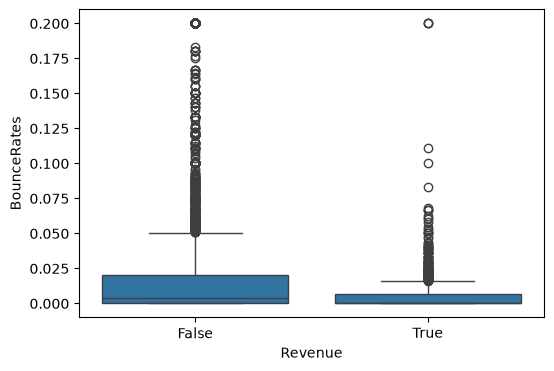

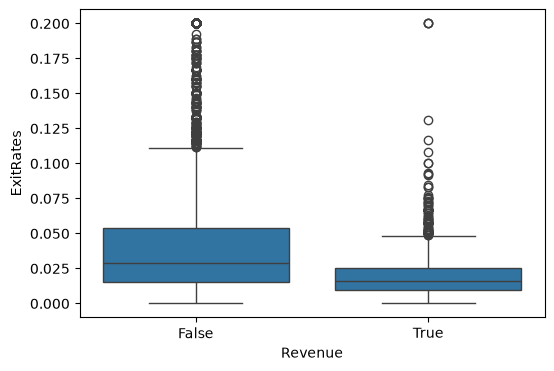

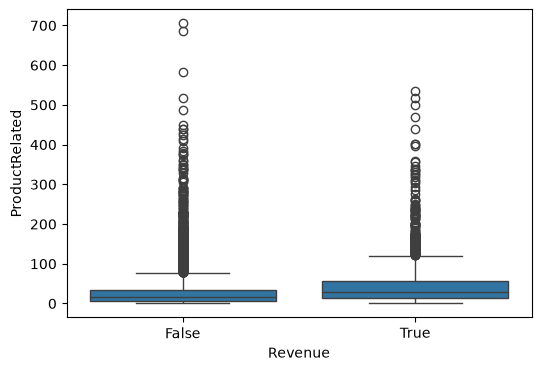

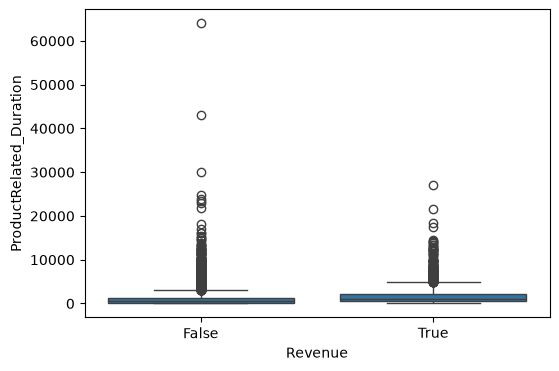

Administrative: 404 outliers
Administrative_Duration: 1172 outliers
Informational: 2631 outliers
Informational_Duration: 2405 outliers
ProductRelated: 987 outliers
ProductRelated_Duration: 961 outliers
BounceRates: 1551 outliers
ExitRates: 1099 outliers
PageValues: 2730 outliers
SpecialDay: 1251 outliers
OperatingSystems: 111 outliers
Browser: 4369 outliers
Region: 511 outliers
TrafficType: 2101 outliers


In [5]:
#eda 
#box plots of variables with revenue 

cols = [
    'BounceRates',
    'ExitRates',
    'ProductRelated',
    'ProductRelated_Duration'
]
for col in cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(
        x='Revenue',
        y=col,
        data=df
    )
    plt.show()    


#outlier detection 
numeric_cols = df.select_dtypes(include=['number']).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {count} outliers")

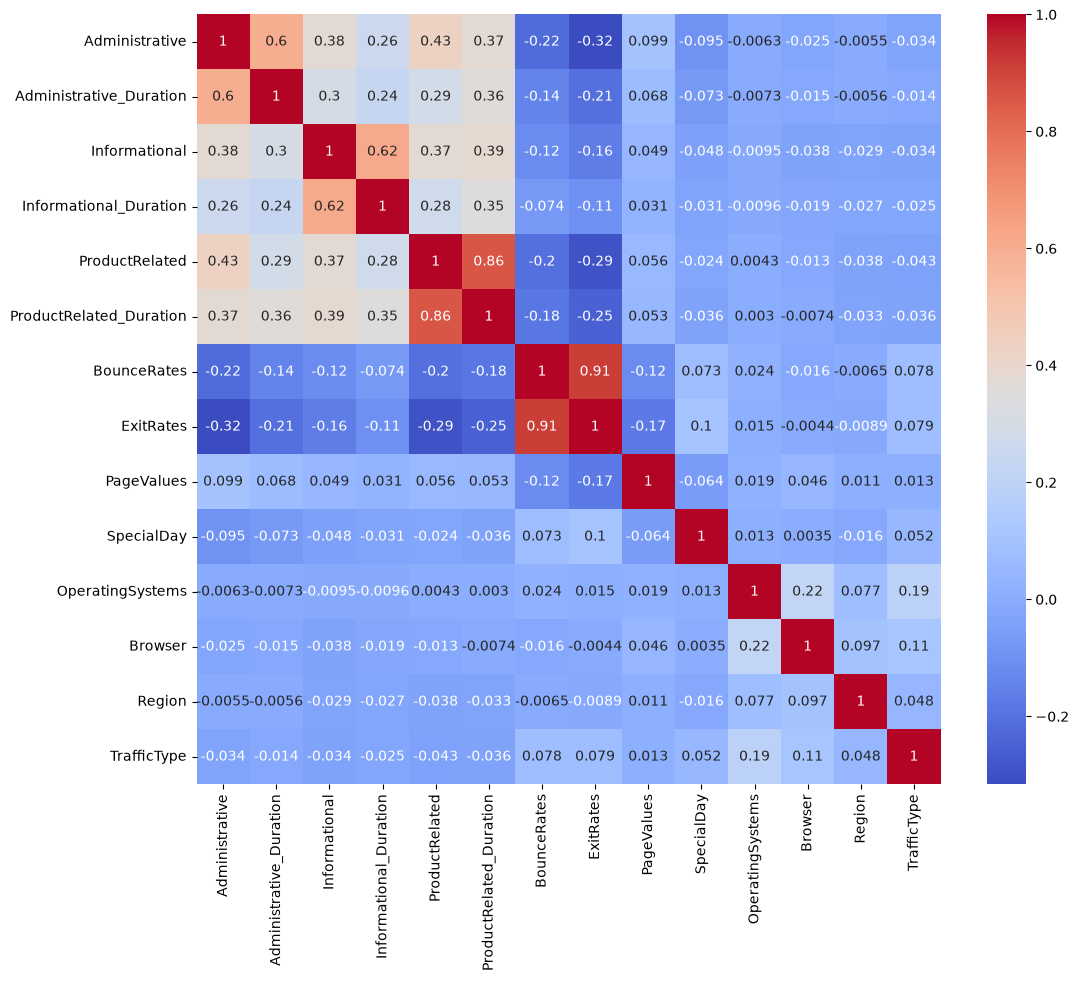

In [6]:
#correlation matrix 
numeric = df.select_dtypes(include=['int64','float64'])
corr = numeric.corr()
plt.figure(figsize=(12,10))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)
plt.show()

In [7]:
#lda
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, roc_auc_score

# Features and target
X = df.drop("Revenue", axis=1)
y = df["Revenue"]

# Convert categorical variables to dummy variables
X = pd.get_dummies(X, drop_first=True)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# LDA
lda = LinearDiscriminantAnalysis()

lda.fit(X_train_scaled, y_train)

# Predictions
y_pred = lda.predict(X_test_scaled)
y_prob = lda.predict_proba(X_test_scaled)[:,1]

# Performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

# Coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'LDA_Coefficient': lda.coef_[0]
})

coef_df['AbsCoeff'] = coef_df['LDA_Coefficient'].abs()

coef_df = coef_df.sort_values(
    by='AbsCoeff',
    ascending=False
)

print(coef_df.head(15))

Accuracy: 0.8751013787510138
ROC-AUC: 0.8981406578167238
                          Feature  LDA_Coefficient  AbsCoeff
8                      PageValues         1.833407  1.833407
7                       ExitRates        -0.578061  0.578061
6                     BounceRates         0.275338  0.275338
20                      Month_May        -0.221165  0.221165
21                      Month_Nov         0.220686  0.220686
15                      Month_Dec        -0.184664  0.184664
19                      Month_Mar        -0.182366  0.182366
5         ProductRelated_Duration         0.160338  0.160338
25  VisitorType_Returning_Visitor        -0.137249  0.137249
4                  ProductRelated         0.124476  0.124476
16                      Month_Feb        -0.089724  0.089724
10               OperatingSystems        -0.072604  0.072604
2                   Informational         0.065037  0.065037
11                        Browser         0.064244  0.064244
18                     Month

In [8]:
#LOGISTIC REGRESSION USING LDA VARIABLES


X = df[['PageValues',
        'ExitRates',
        'BounceRates',
        'Month',
        'ProductRelated',
        'SpecialDay',
        'ProductRelated_Duration',
        'VisitorType']]

y = df['Revenue'] 
X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(
    max_iter=10000,
    random_state=42
)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:,1]

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report
)
print("Accuracy:",
      accuracy_score(y_test, y_pred))
print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred))

coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coefficient': log_reg.coef_[0]
})
coef_df['AbsCoeff'] = abs(coef_df['Coefficient'])

Accuracy: 0.8811841038118411
ROC-AUC: 0.8882234124870616
              precision    recall  f1-score   support

       False       0.89      0.98      0.93      2084
        True       0.74      0.36      0.49       382

    accuracy                           0.88      2466
   macro avg       0.82      0.67      0.71      2466
weighted avg       0.87      0.88      0.86      2466



In [9]:
X = df.drop("Revenue", axis=1)
y = df["Revenue"]
X = pd.get_dummies(X, drop_first=True)
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
#train test split

In [10]:
#decision tree
tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=6
)

tree.fit(X_train_all, y_train_all)

tree_pred_all = tree.predict(X_test_all)
tree_prob_all = tree.predict_proba(X_test_all)[:,1]

print("Tree Accuracy:",
      accuracy_score(y_test_all, tree_pred_all))

print("Tree ROC AUC:",
      roc_auc_score(y_test_all, tree_prob_all))

from sklearn.metrics import (
    classification_report
)
print(classification_report(y_test_all, tree_pred_all))


Tree Accuracy: 0.8941605839416058
Tree ROC AUC: 0.9065863321642834
              precision    recall  f1-score   support

       False       0.92      0.96      0.94      2084
        True       0.70      0.56      0.62       382

    accuracy                           0.89      2466
   macro avg       0.81      0.76      0.78      2466
weighted avg       0.89      0.89      0.89      2466



In [11]:
#random forest
rf_all = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)
rf_all.fit(X_train_all, y_train_all)

rf_all_pred = rf_all.predict(X_test_all)
rf_all_prob = rf_all.predict_proba(X_test_all)[:,1]

auc_all = roc_auc_score(
    y_test_all,
    rf_all_prob
)

print("All Features AUC:", auc_all)

from sklearn.metrics import (
    classification_report
)
print(classification_report(y_test_all, rf_all_pred))


All Features AUC: 0.9193273859171347
              precision    recall  f1-score   support

       False       0.92      0.96      0.94      2084
        True       0.73      0.55      0.63       382

    accuracy                           0.90      2466
   macro avg       0.83      0.76      0.79      2466
weighted avg       0.89      0.90      0.89      2466



In [12]:
#xgboost 
xgb_all= XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

xgb_all.fit(X_train_all, y_train_all)

xgb_all_pred = xgb_all.predict(X_test_all)
xgb_all_prob = xgb_all.predict_proba(X_test_all)[:,1]

print("XGBoost Accuracy:",
      accuracy_score(y_test_all, xgb_all_pred))

print("XGBoost ROC AUC:",
      roc_auc_score(y_test_all, xgb_all_prob))

print("All Features AUC:", auc_all)

from sklearn.metrics import (
    classification_report
)
print(classification_report(y_test_all, xgb_all_pred))


XGBoost Accuracy: 0.9002433090024331
XGBoost ROC AUC: 0.9294412175538382
All Features AUC: 0.9193273859171347
              precision    recall  f1-score   support

       False       0.93      0.96      0.94      2084
        True       0.71      0.59      0.65       382

    accuracy                           0.90      2466
   macro avg       0.82      0.78      0.80      2466
weighted avg       0.89      0.90      0.90      2466



In [13]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score
thresholds = np.arange(0.20, 0.61, 0.05)

for threshold in thresholds:

    pred = (xgb_all_prob >= threshold).astype(int)

    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.20 | Precision: 0.560 | Recall: 0.798 | F1: 0.658
Threshold: 0.25 | Precision: 0.593 | Recall: 0.767 | F1: 0.669
Threshold: 0.30 | Precision: 0.622 | Recall: 0.725 | F1: 0.670
Threshold: 0.35 | Precision: 0.658 | Recall: 0.699 | F1: 0.678
Threshold: 0.40 | Precision: 0.671 | Recall: 0.673 | F1: 0.672
Threshold: 0.45 | Precision: 0.693 | Recall: 0.634 | F1: 0.662
Threshold: 0.50 | Precision: 0.714 | Recall: 0.594 | F1: 0.649
Threshold: 0.55 | Precision: 0.755 | Recall: 0.542 | F1: 0.631
Threshold: 0.60 | Precision: 0.776 | Recall: 0.500 | F1: 0.608


Best Threshold: 0.35
Best Precision: 0.6576354679802956
Best Recall: 0.6989528795811518
Best F1: 0.6776649746192893


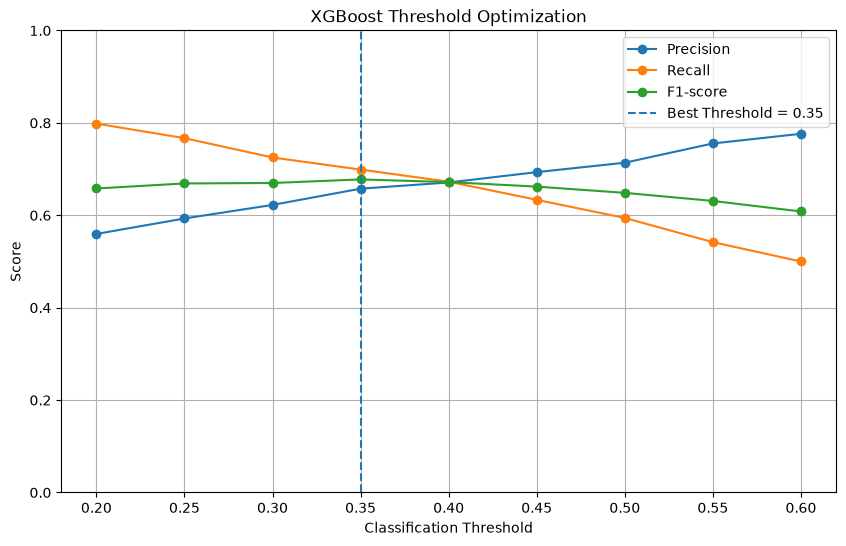

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

# XGBoost predicted probabilities
# Make sure xgb_prob = xgb.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.20, 0.61, 0.05)

precisions = []
recalls = []
f1_scores = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    y_pred_threshold = (xgb_all_prob >= threshold).astype(int)

    # Calculate metrics for purchaser class (True = 1)
    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1)

# Find threshold with highest F1
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best Threshold:", best_threshold)
print("Best Precision:", precisions[best_index])
print("Best Recall:", recalls[best_index])
print("Best F1:", f1_scores[best_index])

# ------------------------------------------------
# Plot
# ------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(thresholds, precisions, marker='o', label='Precision')
plt.plot(thresholds, recalls, marker='o', label='Recall')
plt.plot(thresholds, f1_scores, marker='o', label='F1-score')

# Highlight best threshold
plt.axvline(
    x=best_threshold,
    linestyle='--',
    label=f'Best Threshold = {best_threshold:.2f}'
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("XGBoost Threshold Optimization")
plt.xticks(thresholds)
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

Confusion Matrix at Threshold = 0.35
[[1945  139]
 [ 115  267]]


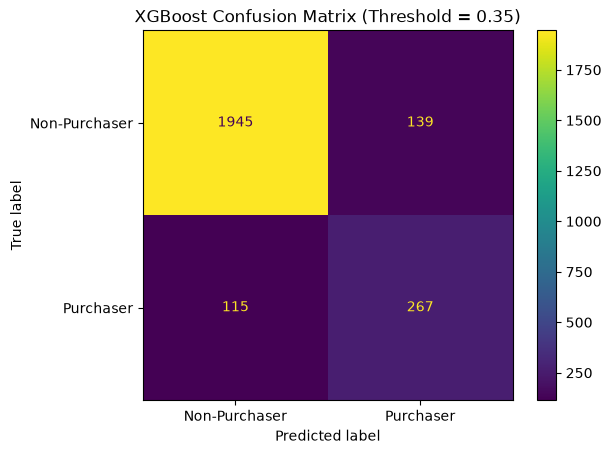

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
threshold = 0.35
xgb_pred = (xgb_all_prob >= threshold).astype(int)
cm = confusion_matrix(y_test, xgb_pred)
print("Confusion Matrix at Threshold = 0.35")
print(cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Purchaser", "Purchaser"]
)

disp.plot()
plt.title("XGBoost Confusion Matrix (Threshold = 0.35)")
plt.show()

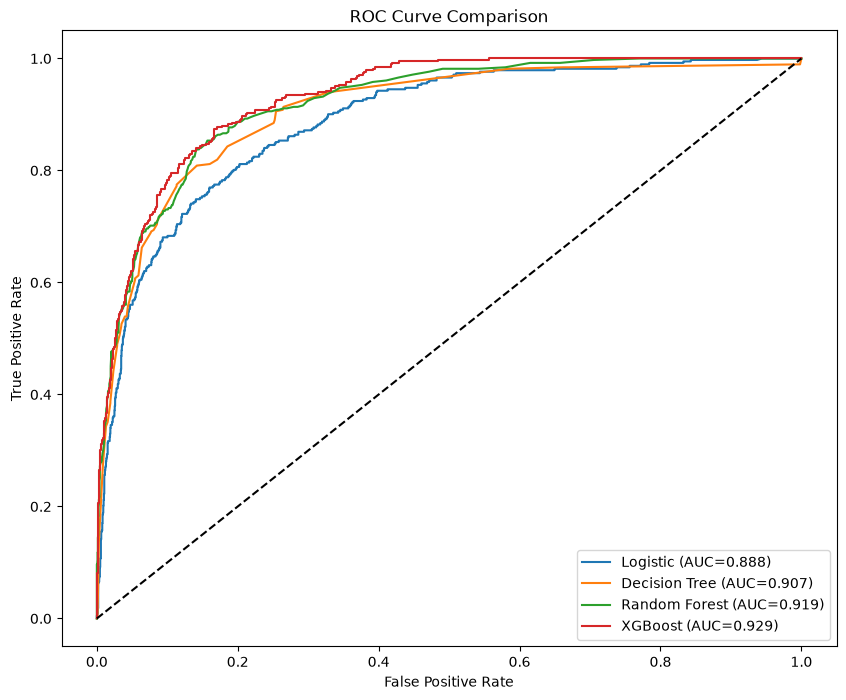

                 Model   ROC_AUC
3              XGBoost  0.929441
2        Random Forest  0.919327
1        Decision Tree  0.906586
0  Logistic Regression  0.888223


In [16]:
#model comparison
plt.figure(figsize=(10,8))

for probs, label in [
    (y_prob, "Logistic"),
    (tree_prob_all, "Decision Tree"),
    (rf_all_prob, "Random Forest"),
    (xgb_all_prob, "XGBoost")
]:

    fpr, tpr, _ = roc_curve(y_test, probs)

    plt.plot(
        fpr,
        tpr,
        label=f"{label} (AUC={roc_auc_score(y_test, probs):.3f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],

    'ROC_AUC': [

        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, tree_prob_all),
        roc_auc_score(y_test, rf_all_prob),
        roc_auc_score(y_test, xgb_all_prob)
    ]
})
print(results.sort_values(
    by='ROC_AUC',
    ascending=False
))

                          Feature  Importance
8                      PageValues    0.371051
7                       ExitRates    0.091276
5         ProductRelated_Duration    0.088176
4                  ProductRelated    0.071694
1         Administrative_Duration    0.057805
6                     BounceRates    0.054902
0                  Administrative    0.042665
13                    TrafficType    0.031189
12                         Region    0.030754
3          Informational_Duration    0.026421
21                      Month_Nov    0.019790
11                        Browser    0.018638
10               OperatingSystems    0.018078
2                   Informational    0.017753
25  VisitorType_Returning_Visitor    0.011700


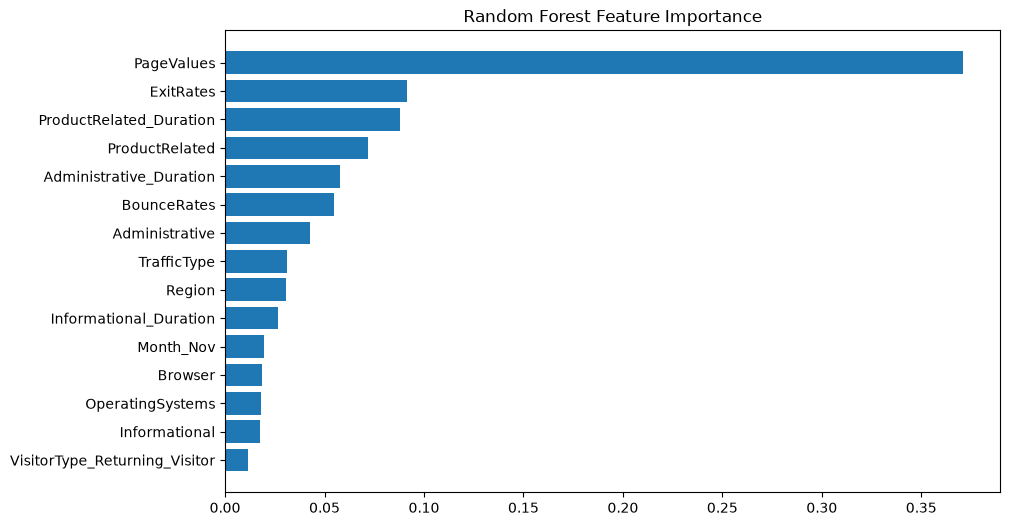

In [17]:
#rf feature importance 
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_all.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

print(importance.head(15))

plt.figure(figsize=(10,6))
plt.barh(
    importance['Feature'][:15],
    importance['Importance'][:15]
)
plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.show()

                          Feature  Importance
8                      PageValues    0.347375
21                      Month_Nov    0.104985
20                      Month_May    0.058775
19                      Month_Mar    0.054862
23                      Month_Sep    0.048765
25  VisitorType_Returning_Visitor    0.031725
6                     BounceRates    0.030096
0                  Administrative    0.025728
4                  ProductRelated    0.024799
5         ProductRelated_Duration    0.023077
22                      Month_Oct    0.021708
17                      Month_Jul    0.021583
18                     Month_June    0.021181
7                       ExitRates    0.021152
14                        Weekend    0.018417


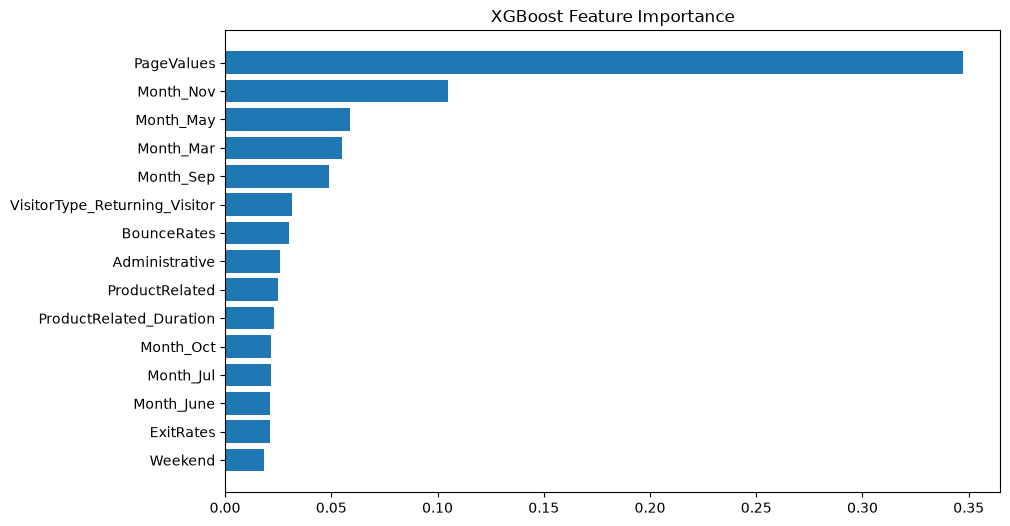

In [18]:
#xgboost feature importance
xgb_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_all.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
    
)

print(xgb_importance.head(15))

plt.figure(figsize=(10,6))
plt.barh(
    xgb_importance['Feature'][:15],
    xgb_importance['Importance'][:15]
)
plt.gca().invert_yaxis()
plt.title("XGBoost Feature Importance")
plt.show()

In [19]:
#logistic regression coefficients 
X_log = df[['PageValues',
            'ExitRates',
            'BounceRates',
            'Month',
            'ProductRelated',
            'SpecialDay',
            'ProductRelated_Duration',
            'VisitorType']]

X_log = pd.get_dummies(X_log, drop_first=True)
log_reg.fit(X_train_scaled, y_train)
coef_df = pd.DataFrame({
    "Feature": X_log.columns,
    "Coefficient": log_reg.coef_[0]
})

coef_df["AbsCoef"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values("AbsCoef", ascending=False)

print(coef_df)



                          Feature  Coefficient   AbsCoef
0                      PageValues     1.539748  1.539748
1                       ExitRates    -0.810770  0.810770
11                      Month_May    -0.267792  0.267792
2                     BounceRates    -0.256713  0.256713
7                       Month_Feb    -0.241705  0.241705
10                      Month_Mar    -0.205377  0.205377
6                       Month_Dec    -0.198411  0.198411
12                      Month_Nov     0.181752  0.181752
5         ProductRelated_Duration     0.102496  0.102496
3                  ProductRelated     0.094308  0.094308
16  VisitorType_Returning_Visitor    -0.085904  0.085904
4                      SpecialDay    -0.054212  0.054212
15              VisitorType_Other    -0.049467  0.049467
9                      Month_June    -0.045736  0.045736
8                       Month_Jul    -0.018423  0.018423
13                      Month_Oct    -0.007972  0.007972
14                      Month_S

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_auc = cross_val_score(
    log_reg,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print("CV AUC scores:", cv_auc)
print("Mean CV AUC:", cv_auc.mean())
print("Std CV AUC:", cv_auc.std())

CV AUC scores: [0.89920981 0.90805913 0.8961611  0.90278611 0.90551791]
Mean CV AUC: 0.9023468130213246
Std CV AUC: 0.004265750809592922


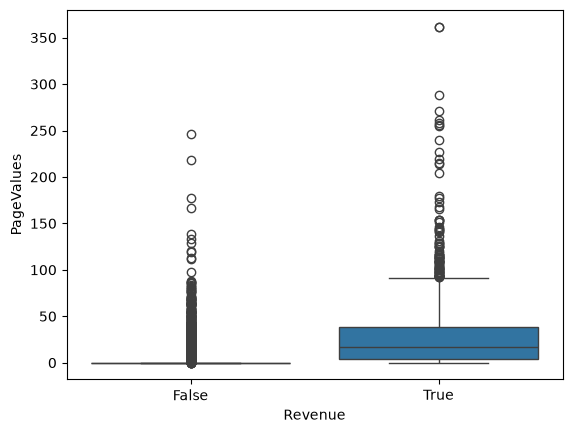

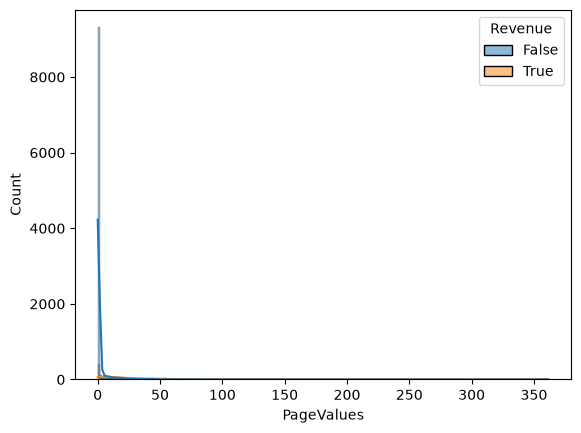

ShapiroResult(statistic=np.float64(0.711025860685856), pvalue=np.float64(2.648170015682441e-49))
ShapiroResult(statistic=np.float64(0.2249004756092956), pvalue=np.float64(9.254585481359894e-110))


C:\Users\ramis\AppData\Local\Programs\Python\Python314\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10422.
  res = hypotest_fun_out(*samples, **kwds)


In [21]:
#shapiro test
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(
    x='Revenue',
    y='PageValues',
    data=df
)
plt.show()


sns.histplot(
    data=df,
    x='PageValues',
    hue='Revenue',
    kde=True
)
plt.show()

from scipy.stats import shapiro

purchasers = df[df['Revenue']==True]['PageValues']
non_purchasers = df[df['Revenue']==False]['PageValues']

print(shapiro(purchasers))
print(shapiro(non_purchasers))


In [22]:
#man whitney u test

from scipy.stats import mannwhitneyu

u_stat, p_value = mannwhitneyu(
    purchasers,
    non_purchasers,
    alternative='two-sided'
)

print("U statistic =", u_stat)
print("p-value =", p_value)

print(
    df.groupby('Revenue')['PageValues']
      .agg(['mean','median','std'])
)

U statistic = 17166757.0
p-value = 0.0
              mean     median        std
Revenue                                 
False     1.975998   0.000000   9.072424
True     27.264518  16.758134  35.191954
